In [1]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

In [2]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [3]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]
vix_yesterday = df["vix"].shift(periods=1)
df["vix_ln_return"]=np.log(df["vix"]/vix_yesterday)
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

In [4]:
df1_part3 = df_part3
idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)

In [5]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()]  #'Wednesday'

# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
years = df_part3['year'].unique()
df_part3['month-year'] = [d.strftime('%b') + str(d.year) for d in df_part3.index]


In [6]:
# Split data into train data(including validation data) and test data
split_ratio = 0.8

data = df_part3.set_index('day')
len_data = df_part3.shape[0]

train_org = df_part3.iloc[:int(len_data*split_ratio),]
test_org = df_part3.iloc[int(len_data*split_ratio):,]

print('train set',train_org.shape)
print('test set',test_org.shape)

train set (227, 17)
test set (57, 17)


In [7]:
df['Num_word'] = df['articles'].apply(lambda x:len(str(x).split())) #Number Of words in main text

<AxesSubplot:title={'center':'Number of words'}>

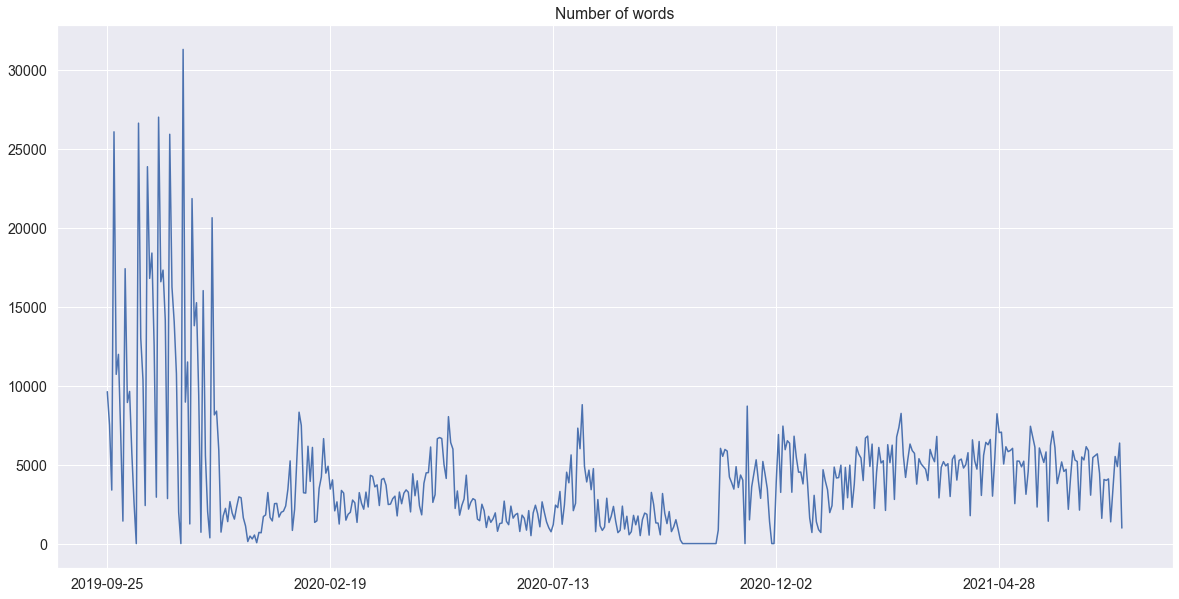

In [8]:
df['Num_word'].plot(figsize=(20, 10),title='Number of words')

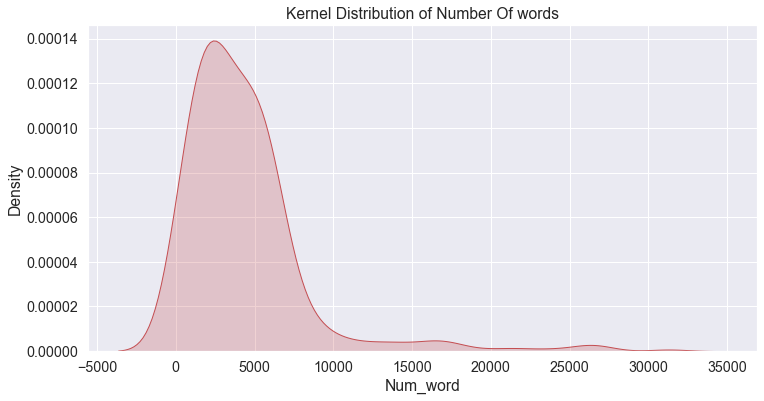

In [9]:
plt.figure(figsize=(12,6))
p1=sns.kdeplot(df['Num_word'], shade=True, color="r").set_title('Kernel Distribution of Number Of words')
# p1=sns.kdeplot(train['Num_word_text'], shade=True, color="b")

In [10]:
def clean_text(text):
    '''Make text lowercase, remove text in square brackets,remove links,remove punctuation
    and remove words containing numbers.'''
    text = str(text).lower()
    text = re.sub('\[.*?\]', '', text)
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    return text

In [11]:
df['articles'] = df['articles'].apply(lambda x:clean_text(x))

In [12]:
df.head()


,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,vix,vix_ln_return,sentiment_ewm,date,Num_word
2019-09-25,15.960000,15.960000,fda approves abbotts low dose rechargefree spi...,1.0,0.015,0.879,0.106,87.603306,12.396694,15.960000,NaN,87.603306,2019-09-25,9627
2019-09-26,16.070000,16.070000,fda approves abbotts low dose rechargefree spi...,1.0,0.022,0.859,0.118,84.285714,15.714286,16.070000,0.006869,85.865520,2019-09-26,7518
2019-09-27,17.219999,17.219999,new data demonstrate strong outcomes for abbot...,0.9998,0.033,0.862,0.105,76.086957,23.913043,17.219999,0.069117,82.290879,2019-09-27,3392
2019-09-30,16.240000,16.240000,partech inc completed the acquisition of asset...,1.0,0.024,0.849,0.127,84.105960,15.894040,16.240000,-0.058594,82.811429,2019-09-30,26095
2019-10-01,18.559999,18.559999,accenture plc presents at all day devops acce...,0.9999,0.021,0.901,0.078,78.787879,21.212121,18.559999,0.133531,81.846518,2019-10-01,10726


In [13]:
from collections import Counter
df['temp_list'] = df['articles'].apply(lambda x:str(x).split())
top = Counter([item for sublist in df['temp_list'] for item in sublist])
temp = pd.DataFrame(top.most_common(200))
temp.columns = ['Common_words','count']
temp.style.background_gradient(cmap='Blues')

,Common_words,count
0,of,61950
1,the,55792
2,to,51369
3,and,44816
4,in,30622
5,a,23260
6,for,22354
7,on,14340
8,inc,13583
9,share,13141


In [18]:
import plotly.express as px
fig = px.bar(temp, x="count", y="Common_words", title='Commmon Words in Text', orientation='h', 
             width=700, height=700,color='Common_words')
fig.show()

In [19]:
fig = px.bar(temp, x="count", y="Common_words", title='Commmon Words in Text', orientation='h', 
             width=700, height=700,color='Common_words')
fig.show()

NameError: name 'temp_neutral' is not defined